In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

Data Selection and reading:

In [4]:
df = pd.read_csv('billboard_hot_100_spotify_audio_features_enriched.csv')
print(df)

                                                 song_id  \
0                              Blinding LightsThe Weeknd   
1      Party Rock AnthemLMFAO Featuring Lauren Bennet...   
2                               Rolling In The DeepAdele   
3                                     CirclesPost Malone   
4                 Macarena (Bayside Boys Mix)Los Del Rio   
...                                                  ...   
32498              Guy for That (Version 161)Post Malone   
32499           Drunk in My Mind feat. GunnaBenson Boone   
32500                       Chemical (Part 2)Post Malone   
32501                    Greedy (Version 2498)Tate McRae   
32502        Rich Baby Daddy feat. Travis ScottSexyy Red   

                                       performer  \
0                                     The Weeknd   
1      LMFAO Featuring Lauren Bennett & GoonRock   
2                                          Adele   
3                                    Post Malone   
4                  

Data Understanding:

In [5]:
print(df.head())

                                             song_id  \
0                          Blinding LightsThe Weeknd   
1  Party Rock AnthemLMFAO Featuring Lauren Bennet...   
2                           Rolling In The DeepAdele   
3                                 CirclesPost Malone   
4             Macarena (Bayside Boys Mix)Los Del Rio   

                                   performer                         song  \
0                                 The Weeknd              Blinding Lights   
1  LMFAO Featuring Lauren Bennett & GoonRock            Party Rock Anthem   
2                                      Adele          Rolling In The Deep   
3                                Post Malone                      Circles   
4                                Los Del Rio  Macarena (Bayside Boys Mix)   

                                       spotify_genre        spotify_track_id  \
0  ['canadian contemporary r&b', 'canadian pop', ...  0sf12qNH5qcw8qpgymFOqD   
1                    ['dance pop', 'pop'

In [6]:
print(df.shape)

(32503, 33)


In [7]:
print(df.columns)

Index(['song_id', 'performer', 'song', 'spotify_genre', 'spotify_track_id',
       'spotify_track_preview_url', 'spotify_track_duration_ms',
       'spotify_track_explicit', 'spotify_track_album', 'danceability',
       'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'spotify_track_popularity', 'peak_position', 'weeks_on_chart',
       'first_week', 'last_week', 'chart_success_tier',
       'hit_longevity_profile', 'acoustic_mood_cluster', 'musical_era',
       'evidence_span', 'cot_rationale', 'confidence_score'],
      dtype='str')


In [8]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32503 entries, 0 to 32502
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   song_id                    32503 non-null  str    
 1   performer                  32503 non-null  str    
 2   song                       32503 non-null  str    
 3   spotify_genre              30903 non-null  str    
 4   spotify_track_id           27397 non-null  str    
 5   spotify_track_preview_url  16763 non-null  str    
 6   spotify_track_duration_ms  27397 non-null  float64
 7   spotify_track_explicit     27397 non-null  object 
 8   spotify_track_album        27391 non-null  str    
 9   danceability               27334 non-null  float64
 10  energy                     27334 non-null  float64
 11  key                        27334 non-null  float64
 12  loudness                   27334 non-null  float64
 13  mode                       27334 non-null  float64
 14  s

In [9]:
print(df.describe())

       spotify_track_duration_ms  danceability        energy           key  \
count               2.739700e+04  27334.000000  27334.000000  27334.000000   
mean                2.187495e+05      0.602767      0.618598      5.267542   
std                 6.486243e+04      0.154385      0.195465      3.544824   
min                 2.968800e+04      0.000000      0.000581      0.000000   
25%                 1.762530e+05      0.501000      0.480000      2.000000   
50%                 2.137080e+05      0.610000      0.634000      5.000000   
75%                 2.474260e+05      0.713000      0.773000      8.000000   
max                 3.079157e+06      0.988000      0.997000     11.000000   

           loudness          mode   speechiness  acousticness  \
count  27334.000000  27334.000000  27334.000000  27334.000000   
mean      -8.529460      0.701910      0.089870      0.293139   
std        3.523031      0.457428      0.101008      0.271639   
min      -28.030000      0.000000    

Data Transformation:

1.dropping 3 columns

In [10]:
df.drop(['spotify_track_preview_url', 'evidence_span', 'cot_rationale'],axis=1,inplace=True)
print(df)

                                                 song_id  \
0                              Blinding LightsThe Weeknd   
1      Party Rock AnthemLMFAO Featuring Lauren Bennet...   
2                               Rolling In The DeepAdele   
3                                     CirclesPost Malone   
4                 Macarena (Bayside Boys Mix)Los Del Rio   
...                                                  ...   
32498              Guy for That (Version 161)Post Malone   
32499           Drunk in My Mind feat. GunnaBenson Boone   
32500                       Chemical (Part 2)Post Malone   
32501                    Greedy (Version 2498)Tate McRae   
32502        Rich Baby Daddy feat. Travis ScottSexyy Red   

                                       performer  \
0                                     The Weeknd   
1      LMFAO Featuring Lauren Bennett & GoonRock   
2                                          Adele   
3                                    Post Malone   
4                  

2.Renaming 3 columns

In [11]:
df=df.rename(columns={
    'first_week':'chart_start_date',
    'last_week':'chart_end_date',
    'spotify_track_popularity':'popularity'
})
print(df.columns)

Index(['song_id', 'performer', 'song', 'spotify_genre', 'spotify_track_id',
       'spotify_track_duration_ms', 'spotify_track_explicit',
       'spotify_track_album', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'popularity', 'peak_position',
       'weeks_on_chart', 'chart_start_date', 'chart_end_date',
       'chart_success_tier', 'hit_longevity_profile', 'acoustic_mood_cluster',
       'musical_era', 'confidence_score'],
      dtype='str')


3.Adding a new column

In [26]:
df['chart_start_date'] = pd.to_datetime(df['chart_start_date'])
df['chart_year']=df['chart_start_date'].dt.year
print(df[['song','chart_start_date','chart_year']].head())

                          song chart_start_date  chart_year
0              Blinding Lights       2019-12-14      2019.0
1            Party Rock Anthem       2011-02-12      2011.0
2          Rolling In The Deep       2010-12-25      2010.0
3                      Circles       2019-09-14      2019.0
4  Macarena (Bayside Boys Mix)       1995-09-02      1995.0


In [13]:
df.shape

(32503, 30)

4.Changing data type 

In [14]:
print(df['spotify_track_duration_ms'].dtype)

float64


In [15]:
df['spotify_track_duration_ms']=df['spotify_track_duration_ms'].fillna(df['spotify_track_duration_ms'].mean()).astype(int)
print(df['spotify_track_duration_ms'].head())

0    201573
1    262173
2    228293
3    215280
4    218749
Name: spotify_track_duration_ms, dtype: int64


5.Grouping Data

In [16]:
grouped_mean=df.groupby('spotify_genre')['energy'].mean()
print(grouped_mean)

spotify_genre
["australian children's music", "children's music"]                      0.741000
["australian children's music"]                                          0.546000
["children's music", 'nursery']                                          0.655000
["children's music"]                                                     0.540400
['21st century classical', 'choral', 'nordic contemporary classical']         NaN
                                                                           ...   
['wind quintet']                                                              NaN
['wu fam']                                                               0.842000
['yacht rock']                                                           0.543056
['yodeling']                                                                  NaN
[]                                                                       0.586464
Name: energy, Length: 3407, dtype: float64


Handling null values

In [17]:
print(df.isnull().sum())

song_id                         0
performer                       0
song                            0
spotify_genre                1600
spotify_track_id             5106
spotify_track_duration_ms       0
spotify_track_explicit       5106
spotify_track_album          5112
danceability                 5169
energy                       5169
key                          5169
loudness                     5169
mode                         5169
speechiness                  5169
acousticness                 5169
instrumentalness             5169
liveness                     5169
valence                      5169
tempo                        5169
time_signature               5169
popularity                   5106
peak_position                   3
weeks_on_chart                  3
chart_start_date                3
chart_end_date                  3
chart_success_tier              0
hit_longevity_profile           0
acoustic_mood_cluster           0
musical_era                     0
confidence_sco

In [18]:
df['popularity'] = df['popularity'].fillna(df['popularity'].mean())
df['danceability'] = df['danceability'].fillna(df['danceability'].mean())
df['liveness'] = df['liveness'].fillna(df['liveness'].mean())
df['acousticness'] = df['acousticness'].fillna(df['acousticness'].mean())
df['energy'] = df['energy'].fillna(df['energy'].mean())

In [19]:
print(df[['popularity', 'danceability', 'liveness','acousticness','energy']].isnull().sum())

popularity      0
danceability    0
liveness        0
acousticness    0
energy          0
dtype: int64


In [20]:
print(df[['popularity', 'danceability', 'liveness','acousticness','energy']])

       popularity  danceability  liveness  acousticness    energy
0        96.00000      0.513000  0.093800      0.001470  0.796000
1        68.00000      0.750000  0.266000      0.018900  0.727000
2        76.00000      0.729000  0.052700      0.131000  0.756000
3        98.00000      0.695000  0.086300      0.192000  0.762000
4        44.75866      0.602767  0.193258      0.293139  0.618598
...           ...           ...       ...           ...       ...
32498    79.00000      0.454000  0.232000      0.270000  0.818000
32499    86.00000      0.791000  0.093000      0.252000  0.774000
32500    55.00000      0.756000  0.072000      0.290000  0.273000
32501    56.00000      0.564000  0.250000      0.391000  0.570000
32502    48.00000      0.690000  0.364000      0.349000  0.818000

[32503 rows x 5 columns]


Insight Generation

top 10 artists based on total chart weeks

In [22]:
top_artists=df.groupby('performer')['weeks_on_chart'].sum()
top_artists=top_artists.sort_values(ascending=False)
print(top_artists.head(10))

performer
Taylor Swift      2671.0
Drake             2141.0
Billie Eilish     1994.0
The Weeknd        1851.0
Post Malone       1698.0
Harry Styles      1620.0
Morgan Wallen     1575.0
Beyonce           1570.0
Benson Boone      1536.0
Kendrick Lamar    1495.0
Name: weeks_on_chart, dtype: float64


the average energy and danceability of songs

In [23]:
print("Average energy:",df['energy'].mean())
print("Average Danceability:",df['danceability'].mean())
print("Average tempo:",df['tempo'].mean())

Average energy: 0.6185977786273505
Average Danceability: 0.6027667373966488
Average tempo: 121.09672832369942


the top 10 most popular songs

In [24]:
popular_songs=df.sort_values(by='popularity',ascending=False)
print(popular_songs[['song','performer','popularity']].head(10))

                                  song              performer  popularity
2185                      Dance Monkey            Tones And I       100.0
1127    Montero (Call Me By Your Name)              Lil Nas X       100.0
2251                           Roxanne         Arizona Zervas        99.0
3                              Circles            Post Malone        98.0
1170                          Memories               Maroon 5        98.0
13536                             Tusa  Karol G & Nicki Minaj        97.0
1143                   Don't Start Now               Dua Lipa        97.0
6896                           Falling          Trevor Daniel        97.0
58     All I Want For Christmas Is You           Mariah Carey        97.0
4245               everything i wanted          Billie Eilish        97.0


the number of songs in each musical era

In [25]:
era_count=df.groupby('musical_era')['song'].count()
print(era_count)

musical_era
digital_streaming_explosion        8889
golden_rock_soul_era              13077
hyper_streaming_short_form_era     3000
mtv_synth_pop_boom                 7537
Name: song, dtype: int64


Data Visualization

In [27]:
year_songs=df.groupby('chart_year')['song'].count()
print(year_songs)

chart_year
1958.0    353
1959.0    573
1960.0    609
1961.0    677
1962.0    659
         ... 
2022.0    595
2023.0    586
2024.0    600
2025.0    569
2026.0    326
Name: song, Length: 69, dtype: int64


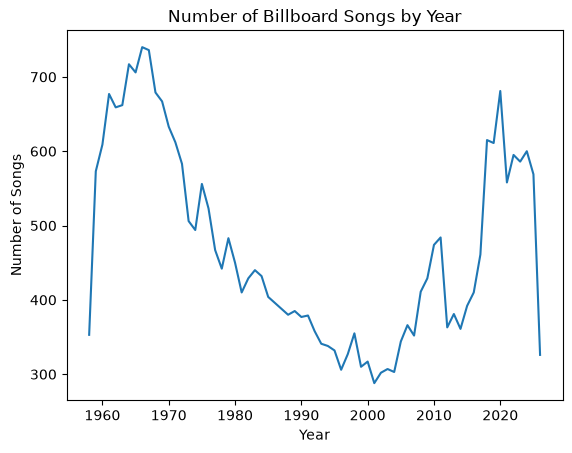

In [30]:
plt.plot(year_songs.index, year_songs.values)

plt.xlabel('Year')
plt.ylabel('Number of Songs')
plt.title('Number of Billboard Songs by Year')

plt.show()

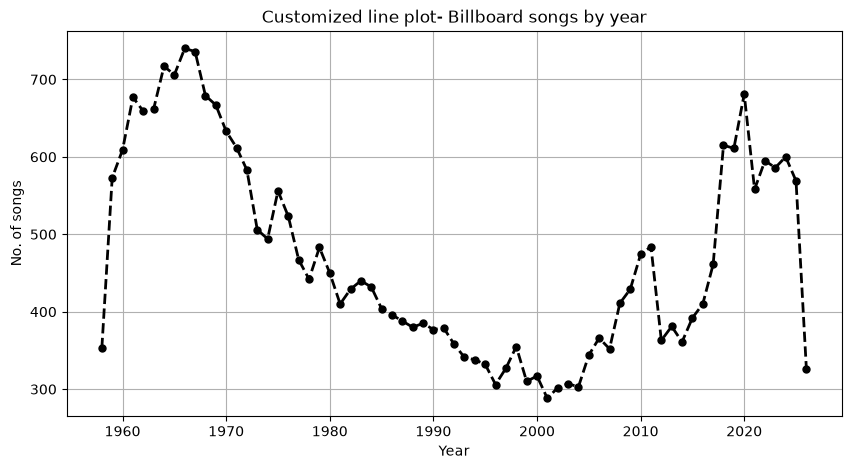

In [36]:
plt.figure(figsize=(10,5))
plt.plot(year_songs.index,year_songs.values,color='black',linestyle='--',marker='o',linewidth=2,markersize=5)
plt.xlabel('Year')
plt.ylabel('No. of songs')
plt.title('Customized line plot- Billboard songs by year')
plt.grid(True)
plt.show()

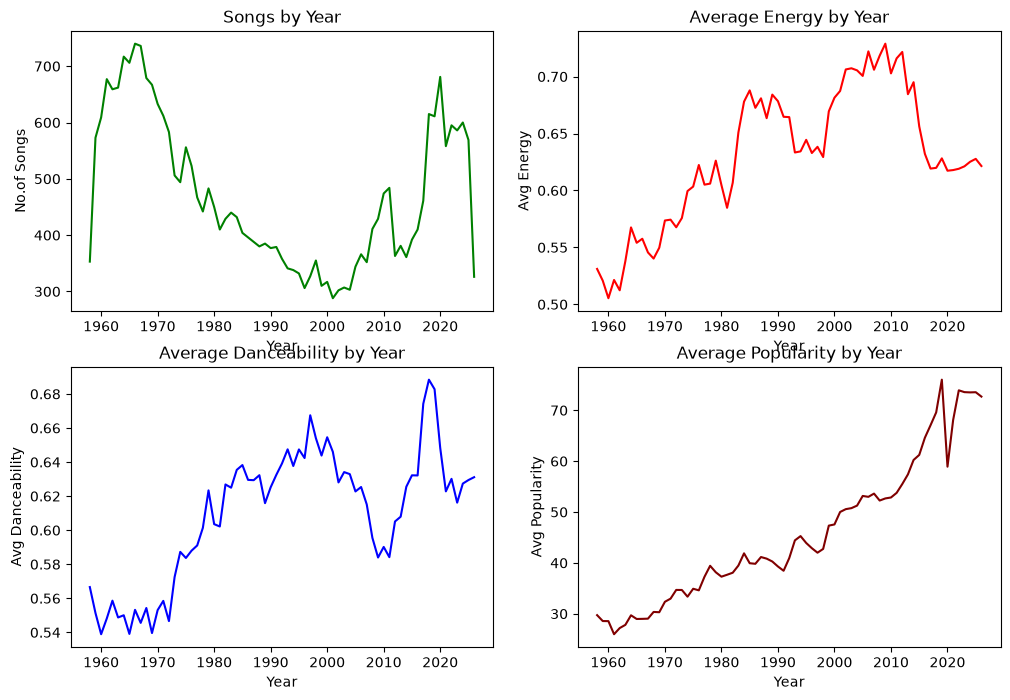

In [40]:
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.plot(year_songs.index, year_songs.values, color='green')
plt.title('Songs by Year')
plt.xlabel('Year')
plt.ylabel('No.of Songs')

plt.subplot(2,2,2)
year_energy = df.groupby('chart_year')['energy'].mean()
plt.plot(year_energy.index, year_energy.values, color='red')
plt.title('Average Energy by Year')
plt.xlabel('Year')
plt.ylabel('Avg Energy')

plt.subplot(2,2,3)
year_danceability = df.groupby('chart_year')['danceability'].mean()
plt.plot(year_danceability.index, year_danceability.values, color='blue')
plt.title('Average Danceability by Year')
plt.xlabel('Year')
plt.ylabel('Avg Danceability')

plt.subplot(2,2,4)
year_popularity = df.groupby('chart_year')['popularity'].mean()
plt.plot(year_popularity.index, year_popularity.values, color='maroon')
plt.title('Average Popularity by Year')
plt.xlabel('Year')
plt.ylabel('Avg Popularity')
plt.show()

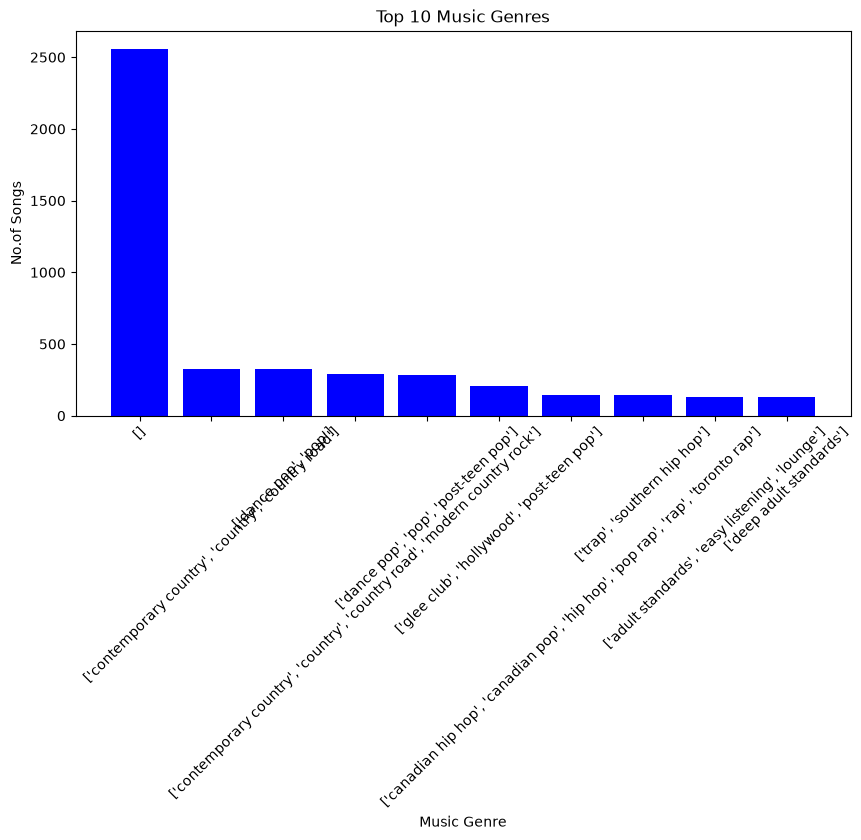

In [42]:
genre=df['spotify_genre'].value_counts().head(10)
plt.figure(figsize=(10,5))
plt.bar(genre.index,genre.values,color='blue')
plt.title('Top 10 Music Genres')
plt.xlabel('Music Genre')
plt.ylabel('No.of Songs')
plt.xticks(rotation=45)
plt.show()


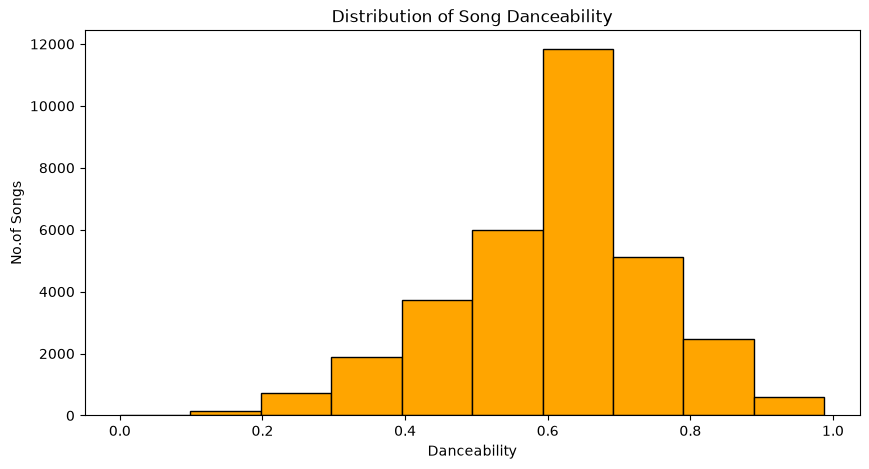

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(df['danceability'], bins=10, color='orange', edgecolor='black')
plt.xlabel('Danceability')
plt.ylabel('No.of Songs')
plt.title('Distribution of Song Danceability')

plt.show()

Text(0.5, 1.0, 'Energy Vs Danceability')

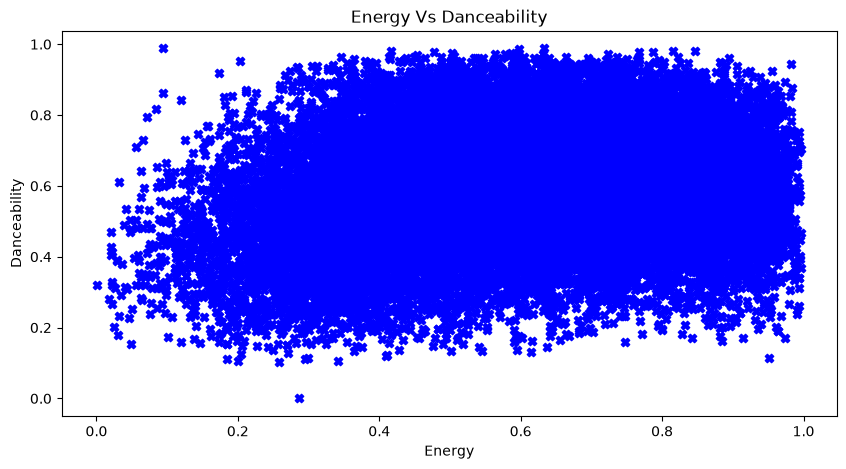

In [47]:
plt.figure(figsize=(10,5))
plt.scatter(df['energy'],df['danceability'],color='blue',marker='X')
plt.xlabel('Energy')
plt.ylabel('Danceability')
plt.title('Energy Vs Danceability')

spotify_genre
[]                                                                            2557
['contemporary country', 'country', 'country road']                            326
['dance pop', 'pop']                                                           323
['contemporary country', 'country', 'country road', 'modern country rock']     294
['dance pop', 'pop', 'post-teen pop']                                          285
Name: count, dtype: int64


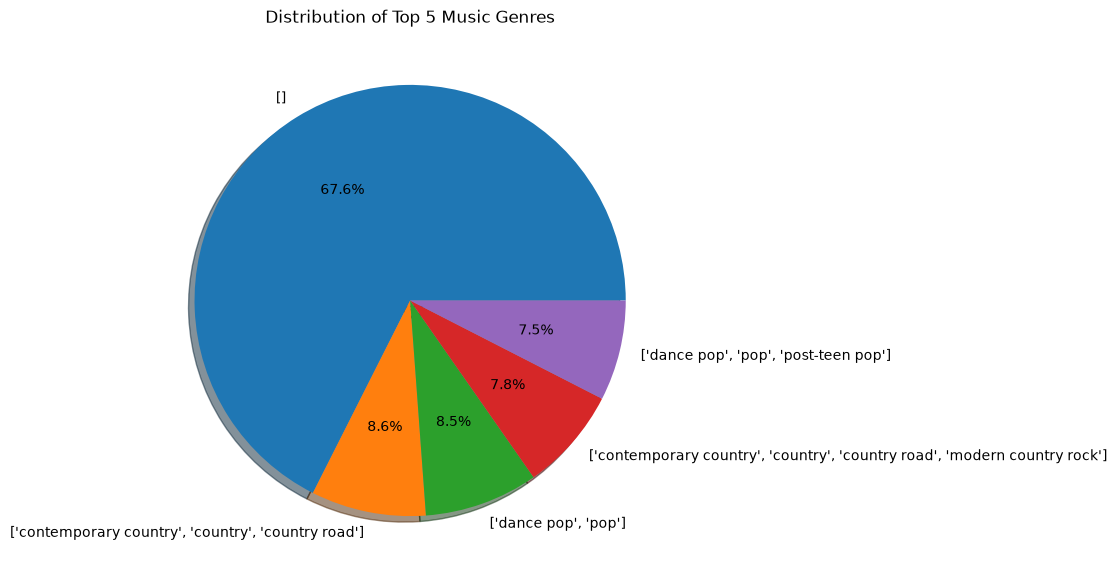

In [51]:
genre = df['spotify_genre'].value_counts().head(5)
print(genre)
plt.figure(figsize=(7,7))
plt.pie(genre.values,labels=genre.index,autopct='%1.1f%%',shadow=True)
plt.title('Distribution of Top 5 Music Genres')
plt.show()

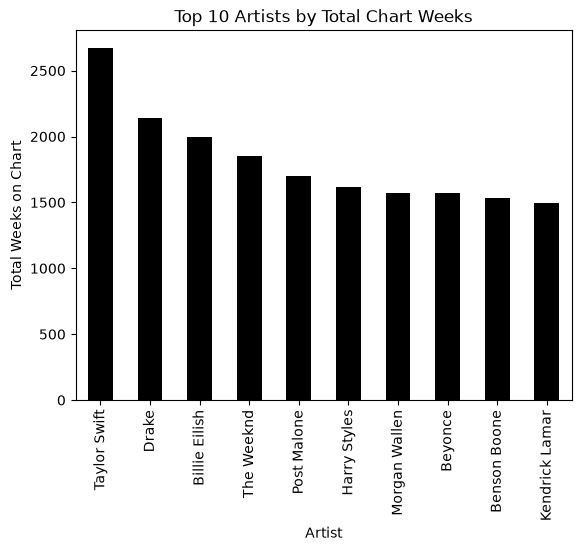

In [52]:
artist_weeks = df.groupby('performer')['weeks_on_chart'].sum()
artist_weeks = artist_weeks.sort_values(ascending=False).head(10)
artist_weeks.plot(kind='bar', color='black')
plt.xlabel('Artist')
plt.ylabel('Total Weeks on Chart')
plt.title('Top 10 Artists by Total Chart Weeks')
plt.show()